Name: Eileen Yang
<br>
Github Username: eileeny32
<br>
USC ID: 6974019134

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, RocCurveDisplay, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import KernelPCA

In [71]:
def train_svm(X_train, y_train, X_test=None, final=False, c=0, iter=3000):
  if final:
    norm = Normalizer()
    X_train_norm = pd.DataFrame(norm.transform(X_train))
    X_test_norm = pd.DataFrame(norm.transform(X_test))
    scale = StandardScaler()
    X_train_scale = scale.fit_transform(X_train)
    X_test_scale = scale.transform(X_test)
    svm = LinearSVC(penalty='l1', C=c, max_iter=iter)
    svm.fit(X_train_scale, y_train)
    return X_train_scale, X_test_scale, svm
  pipe = Pipeline([
      ('norm', Normalizer()),
      ('scale', StandardScaler()),
      ('svm', LinearSVC(penalty='l1', max_iter=iter))
  ])
  param_grid = {'svm__C': [0.0001, 0.001, 0.01]}
  cv = GridSearchCV(
      estimator=pipe,
      param_grid=param_grid,
      cv=5,
      scoring='accuracy'
  )
  cv.fit(X_train, y_train)
  return cv.best_params_['svm__C']


def display(y_pred_train, y_pred_test, y_probs_train, y_probs_test, y_train, y_test):
  cm_train = confusion_matrix(y_train, y_pred_train)
  cm_test = confusion_matrix(y_test, y_pred_test)
  fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_probs_train)
  fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_probs_test)
  auc_train = roc_auc_score(y_train, y_probs_train)
  auc_test = roc_auc_score(y_test, y_probs_test)
  fig, axs = plt.subplots(1, 4, figsize=(12, 5))
  disp_cm_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=np.array([0,1]))
  disp_cm_train.plot(ax=axs[0])
  axs[0].set_title('Train Set Confusion Matrix')
  disp_cm_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=np.array([0,1]))
  disp_cm_test.plot(ax=axs[1])
  axs[1].set_title('Test Set Confusion Matrix')
  disp_roc_train = RocCurveDisplay(fpr=fpr_train, tpr=tpr_train, roc_auc=auc_train)
  disp_roc_train.plot(ax=axs[2])
  axs[2].set_title('Train Set ROC Curve')
  disp_roc_test = RocCurveDisplay(fpr=fpr_test, tpr=tpr_test, roc_auc=auc_test)
  disp_roc_test.plot(ax=axs[3])
  axs[3].set_title('Test Set ROC Curve')
  plt.tight_layout()
  plt.show()

def gen_train_test(X_pos, y_pos, X_neg, y_neg):
  X_pos_train, X_pos_test, y_pos_train, y_pos_test = train_test_split(X_pos, y_pos, test_size=0.2)
  X_neg_train, X_neg_test, y_neg_train, y_neg_test = train_test_split(X_neg, y_neg, test_size=0.2)
  X_train = pd.concat([X_pos_train, X_neg_train], ignore_index=True)
  X_test = pd.concat([X_pos_test, X_neg_test], ignore_index=True)
  y_train = pd.concat([y_pos_train, y_neg_train], ignore_index=True).astype(int)
  y_test = pd.concat([y_pos_test, y_neg_test], ignore_index=True).astype(int)
  return X_train, X_test, y_train, y_test

The following code block completes 1(a).

In [21]:
df = pd.read_csv('wdbc.data', header=None)
y = df[1]
X = df.drop(columns=[0, 1])
y_pos = y[y == 'M']
y_neg = y[y == 'B']
X_pos = X[y == 'M']
X_neg = X[y == 'B']
y_pos[:] = 1
y_neg[:] = 0

The following code block completes 1(b)(i).

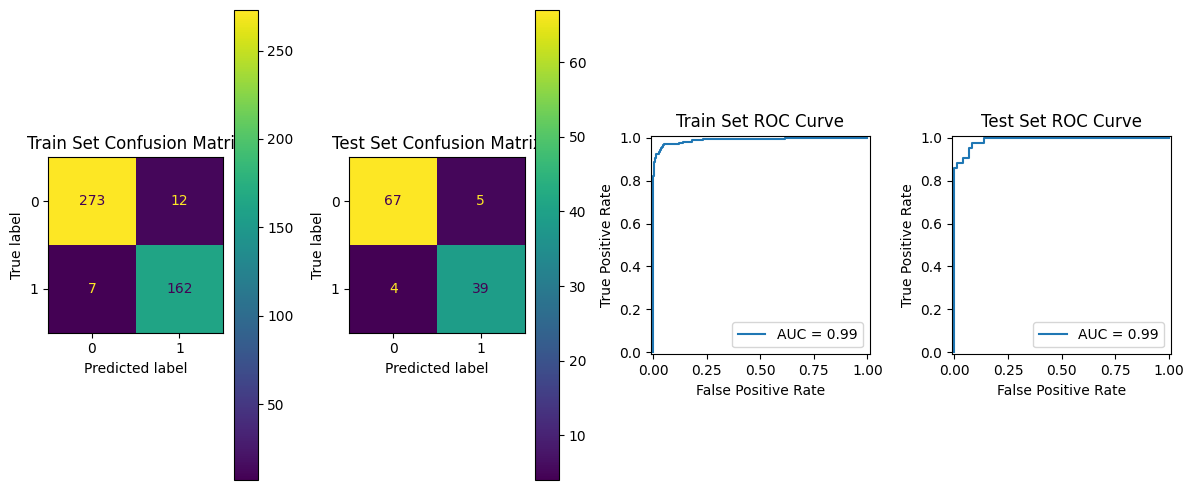

Supervised learning metric averages: {'Train Accuracy': np.float64(0.9545521292217323), 'Test Accuracy': np.float64(0.9446376811594203), 'Train Precision': np.float64(0.9271140399368275), 'Test Precision': np.float64(0.9227935799661144), 'Train Recall': np.float64(0.9528599605522687), 'Test Recall': np.float64(0.9310077519379847), 'Train F1': np.float64(0.9397903968720889), 'Test F1': np.float64(0.9262178339994077), 'Train AUC': np.float64(0.9908571230838435), 'Test AUC': np.float64(0.9880490956072351)}


In [61]:
sup_acc = []
sup_prec = []
sup_rec = []
sup_f1 = []
sup_auc = []
for i in range(30):
  X_train, X_test, y_train, y_test = gen_train_test(X_pos, y_pos, X_neg, y_neg)
  best_C = train_svm(X_train, y_train)
  X_train_scale, X_test_scale, svm = train_svm(X_train, y_train, X_test, final=True, c=best_C)
  y_pred_train = svm.predict(X_train_scale)
  y_probs_train = svm.decision_function(X_train_scale)
  y_pred_test = svm.predict(X_test_scale)
  y_probs_test = svm.decision_function(X_test_scale)
  sup_acc.append([accuracy_score(y_train, y_pred_train), accuracy_score(y_test, y_pred_test)])
  sup_prec.append([precision_score(y_train, y_pred_train), precision_score(y_test, y_pred_test)])
  sup_rec.append([recall_score(y_train, y_pred_train), recall_score(y_test, y_pred_test)])
  sup_f1.append([f1_score(y_train, y_pred_train), f1_score(y_test, y_pred_test)])
  sup_auc.append([roc_auc_score(y_train, y_probs_train), roc_auc_score(y_test, y_probs_test)])
  if i == 8:
    display(y_pred_train, y_pred_test, y_probs_train, y_probs_test, y_train, y_test)
sup_avgs = {'Train Accuracy': np.mean(sup_acc, axis=0)[0], 'Test Accuracy': np.mean(sup_acc, axis=0)[1], 'Train Precision': np.mean(sup_prec, axis=0)[0], 'Test Precision': np.mean(sup_prec, axis=0)[1], 'Train Recall': np.mean(sup_rec, axis=0)[0], 'Test Recall': np.mean(sup_rec, axis=0)[1], 'Train F1': np.mean(sup_f1, axis=0)[0], 'Test F1': np.mean(sup_f1, axis=0)[1], 'Train AUC': np.mean(sup_auc, axis=0)[0], 'Test AUC': np.mean(sup_auc, axis=0)[1]}
print(f'Supervised learning metric averages: {sup_avgs}')

The following code block completes 1(b)(ii).

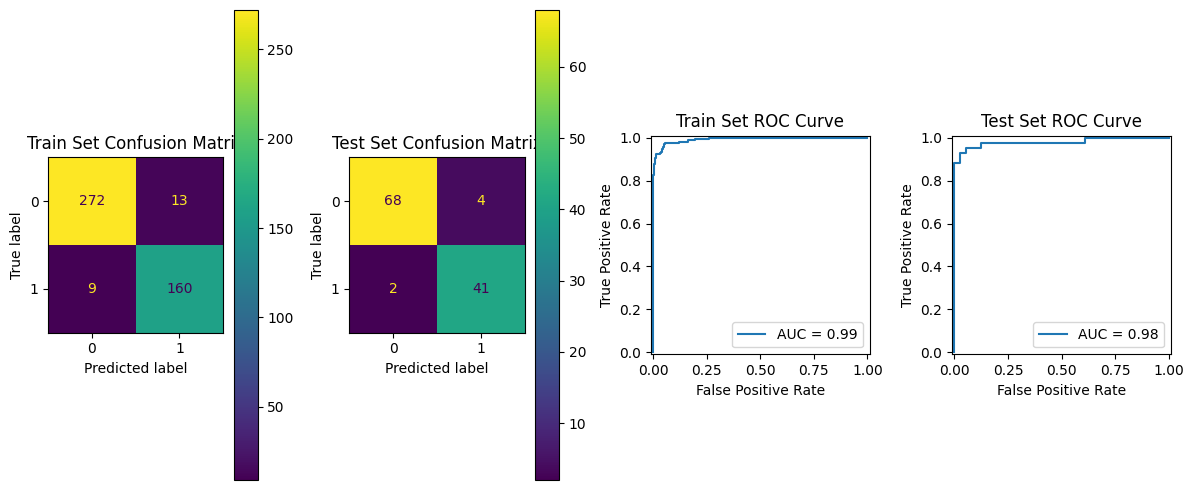

Semi-supervised learning metric averages: {'Train Accuracy': np.float64(0.9536710719530102), 'Test Accuracy': np.float64(0.9440579710144926), 'Train Precision': np.float64(0.9264905089726674), 'Test Precision': np.float64(0.9188165786003321), 'Train Recall': np.float64(0.9510848126232746), 'Test Recall': np.float64(0.9341085271317833), 'Train F1': np.float64(0.9385944043184039), 'Test F1': np.float64(0.925962832934827), 'Train AUC': np.float64(0.9906031350565763), 'Test AUC': np.float64(0.9885443583118001)}


In [66]:
semi_acc = []
semi_prec = []
semi_rec = []
semi_f1 = []
semi_auc = []
for i in range(30):
  X_train, X_test, y_train, y_test = gen_train_test(X_pos, y_pos, X_neg, y_neg)
  X_train_label, X_train_unlabel, y_train_label, y_train_unlabel = train_test_split(X_train, y_train, test_size=0.5)
  for j in range(X_train_unlabel.shape[0]):
    best_C = train_svm(X_train_label, y_train_label)
    _, X_train_unlabel_scale, svm = train_svm(X_train_label, y_train_label, X_train_unlabel, final=True, c=best_C)
    idx = np.argmax(np.abs(svm.decision_function(X_train_unlabel_scale)))
    y_new = svm.predict(X_train_unlabel_scale[idx].reshape(1, -1))
    X_train_label = pd.concat([X_train_label, X_train_unlabel.iloc[[idx]]], ignore_index=True)
    y_train_label = pd.concat([y_train_label, pd.Series(y_new)], ignore_index=True)
    X_train_unlabel = X_train_unlabel.drop(X_train_unlabel.index[idx])
    y_train_unlabel = y_train_unlabel.drop(y_train_unlabel.index[idx])
  final_best_C = train_svm(X_train_label, y_train_label)
  X_train_scale, X_test_scale, final_svm = train_svm(X_train, y_train, X_test, final=True, c=final_best_C)
  y_pred_train = final_svm.predict(X_train_scale)
  y_probs_train = final_svm.decision_function(X_train_scale)
  y_pred_test = final_svm.predict(X_test_scale)
  y_probs_test = final_svm.decision_function(X_test_scale)
  semi_acc.append([accuracy_score(y_train, y_pred_train), accuracy_score(y_test, y_pred_test)])
  semi_prec.append([precision_score(y_train, y_pred_train), precision_score(y_test, y_pred_test)])
  semi_rec.append([recall_score(y_train, y_pred_train), recall_score(y_test, y_pred_test)])
  semi_f1.append([f1_score(y_train, y_pred_train), f1_score(y_test, y_pred_test)])
  semi_auc.append([roc_auc_score(y_train, y_probs_train), roc_auc_score(y_test, y_probs_test)])
  if i == 8:
    display(y_pred_train, y_pred_test, y_probs_train, y_probs_test, y_train, y_test)
semi_avgs = {'Train Accuracy': np.mean(semi_acc, axis=0)[0], 'Test Accuracy': np.mean(semi_acc, axis=0)[1], 'Train Precision': np.mean(semi_prec, axis=0)[0], 'Test Precision': np.mean(semi_prec, axis=0)[1], 'Train Recall': np.mean(semi_rec, axis=0)[0], 'Test Recall': np.mean(semi_rec, axis=0)[1], 'Train F1': np.mean(semi_f1, axis=0)[0], 'Test F1': np.mean(semi_f1, axis=0)[1], 'Train AUC': np.mean(semi_auc, axis=0)[0], 'Test AUC': np.mean(semi_auc, axis=0)[1]}
print(f'Semi-supervised learning metric averages: {semi_avgs}')

The following code block completes 1(b)(iii). To make sure KMeans is not stuck in a local minimum, we set n_init to 10 (for every KMeans instance, KMeans is instantiated 10 times and the best starting point picked to keep) and also scaled the data so that one very large-valued feature would not skew the clustering algorithm. However, we did not normalize the data as that would have restricted every sample vector to the unit ball, which would have made it harder to determine ideal clusters.

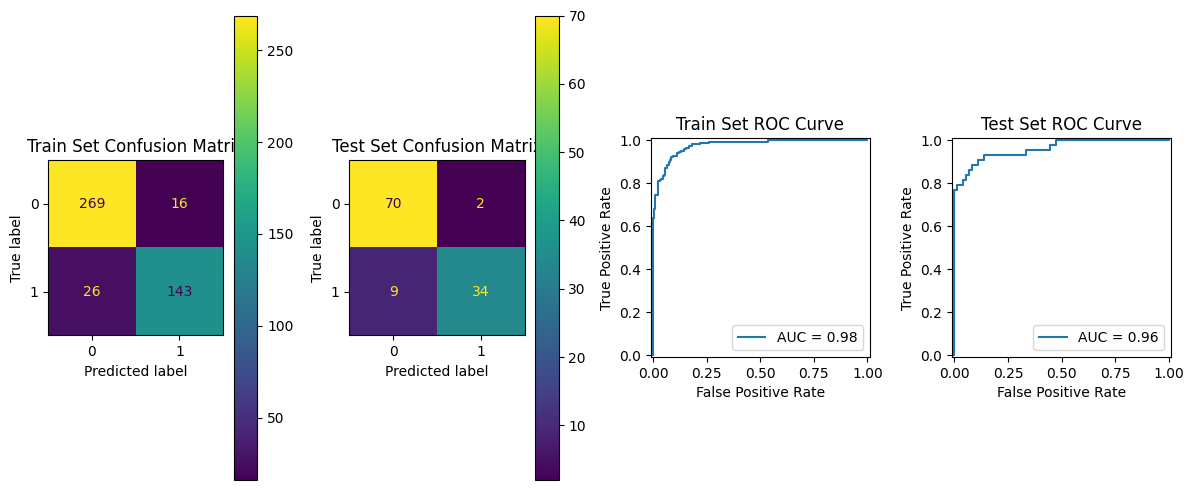

Unsupervised learning (no kernels) metric averages: {'Train Accuracy': np.float64(0.9124082232011748), 'Test Accuracy': np.float64(0.8999999999999997), 'Train Precision': np.float64(0.9244624561032794), 'Test Precision': np.float64(0.9142537152108304), 'Train Recall': np.float64(0.8331360946745563), 'Test Recall': np.float64(0.8100775193798451), 'Train F1': np.float64(0.8762418779632124), 'Test F1': np.float64(0.8575561314958804), 'Train AUC': np.float64(0.9757112702861688), 'Test AUC': np.float64(0.9690245478036176)}


In [24]:
uns_acc = []
uns_prec = []
uns_rec = []
uns_f1 = []
uns_auc = []
kmeans = KMeans(n_clusters=2, n_init=10)
for i in range(30):
  X_train, X_test, y_train, y_test = gen_train_test(X_pos, y_pos, X_neg, y_neg)
  scale = StandardScaler()
  X_train_scale = scale.fit_transform(X_train)
  y_pred = kmeans.fit_predict(X_train_scale)
  zero = np.sum(y_train[y_pred == 0])
  one = np.sum(y_train[y_pred == 1])
  if zero > one:
    pos_cluster = 0
  else:
    pos_cluster = 1
  dists = kmeans.transform(X_train_scale)
  y_pred_total = []
  y_train_total = []
  cluster_labels = []
  for j in range(2):
    cluster_dists = dists[:, j]
    idxs = np.argsort(cluster_dists)[:30]
    label = y_train.iloc[idxs].value_counts().index[0]
    cluster_labels.append(label)
    X_train_scale_cluster = X_train_scale[y_pred == j]
    y_train_cluster = y_train[y_pred == j]
    y_train_total.extend(y_train_cluster)
    y_pred_cluster = np.full(len(y_train_cluster), label)
    y_pred_total.extend(y_pred_cluster)
  exp_dists = np.exp(-dists)
  y_probs = exp_dists[:, pos_cluster] / np.sum(exp_dists, axis=1)
  y_probs_total = []
  for j in range(2):
    y_probs_total.extend(y_probs[y_pred == j])
  X_test_scale = scale.transform(X_test)
  y_pred_raw = kmeans.predict(X_test_scale)
  y_pred_test = [cluster_labels[i] for i in y_pred_raw]
  test_dists = kmeans.transform(X_test_scale)
  exp_test_dists = np.exp(-test_dists)
  y_probs_test = exp_test_dists[:, pos_cluster] / np.sum(exp_test_dists, axis=1)
  uns_acc.append([accuracy_score(y_train_total, y_pred_total), accuracy_score(y_test, y_pred_test)])
  uns_prec.append([precision_score(y_train_total, y_pred_total), precision_score(y_test, y_pred_test)])
  uns_rec.append([recall_score(y_train_total, y_pred_total), recall_score(y_test, y_pred_test)])
  uns_f1.append([f1_score(y_train_total, y_pred_total), f1_score(y_test, y_pred_test)])
  uns_auc.append([roc_auc_score(y_train_total, y_probs_total), roc_auc_score(y_test, y_probs_test)])
  if i == 8:
    display(y_pred_total, y_pred_test, y_probs_total, y_probs_test, y_train_total, y_test)
uns_avgs = {'Train Accuracy': np.mean(uns_acc, axis=0)[0], 'Test Accuracy': np.mean(uns_acc, axis=0)[1], 'Train Precision': np.mean(uns_prec, axis=0)[0], 'Test Precision': np.mean(uns_prec, axis=0)[1], 'Train Recall': np.mean(uns_rec, axis=0)[0], 'Test Recall': np.mean(uns_rec, axis=0)[1], 'Train F1': np.mean(uns_f1, axis=0)[0], 'Test F1': np.mean(uns_f1, axis=0)[1], 'Train AUC': np.mean(uns_auc, axis=0)[0], 'Test AUC': np.mean(uns_auc, axis=0)[1]}
print(f'Unsupervised learning (no kernels) metric averages: {uns_avgs}')

The following code block completes 1(b)(iv). In order to be able to use predict() on X_test, I projected the samples onto the RBF embedding space and ran KMeans on the projections, which is equivalent to running spectral clustering with RBF kernel on the original dataset.

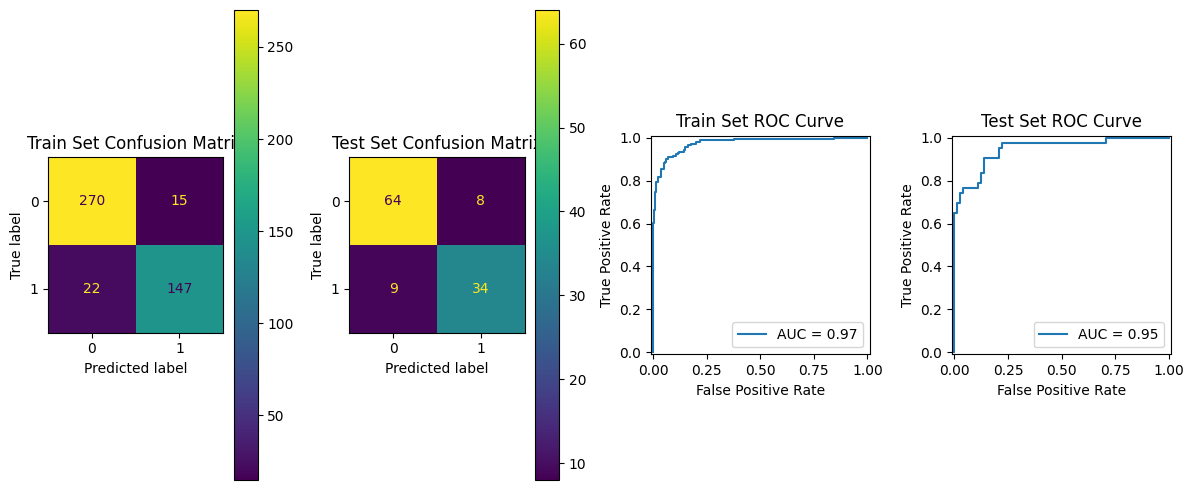

Unsupervised learning (RBF kernel) metric averages: {'Train Accuracy': np.float64(0.905947136563877), 'Test Accuracy': np.float64(0.90231884057971), 'Train Precision': np.float64(0.8907353429388416), 'Test Precision': np.float64(0.8842317083807202), 'Train Recall': np.float64(0.8520710059171601), 'Test Recall': np.float64(0.8519379844961242), 'Train F1': np.float64(0.8708634979187421), 'Test F1': np.float64(0.8666926177493649), 'Train AUC': np.float64(0.9703200802795947), 'Test AUC': np.float64(0.9689707149009473)}


In [43]:
spec_acc = []
spec_prec = []
spec_rec = []
spec_f1 = []
spec_auc = []
spec = Pipeline([
    ('kernel', KernelPCA(n_components=2, kernel='rbf', gamma=0.01)), # this gamma creates clusters with same balance as training dataset
    ('scale', StandardScaler()),
    ('kmeans', KMeans(n_clusters=2, n_init=10))
])
for i in range(30):
  X_train, X_test, y_train, y_test = gen_train_test(X_pos, y_pos, X_neg, y_neg)
  scale = StandardScaler()
  X_train_scale = scale.fit_transform(X_train)
  y_pred = spec.fit_predict(X_train_scale)
  zero = np.sum(y_train[y_pred == 0])
  one = np.sum(y_train[y_pred == 1])
  if zero > one:
    pos_cluster = 0
  else:
    pos_cluster = 1
  X_train_proj = spec.named_steps['scale'].transform(spec.named_steps['kernel'].transform(X_train_scale))
  dists = spec.named_steps['kmeans'].transform(X_train_proj)
  y_pred_total = []
  y_train_total = []
  cluster_labels = []
  for j in range(2):
    cluster_dists = dists[:, j]
    idxs = np.argsort(cluster_dists)[:30]
    label = y_train.iloc[idxs].value_counts().index[0]
    cluster_labels.append(label)
    X_train_scale_cluster = X_train_scale[y_pred == j]
    y_train_cluster = y_train[y_pred == j]
    y_train_total.extend(y_train_cluster)
    y_pred_cluster = np.full(len(y_train_cluster), label)
    y_pred_total.extend(y_pred_cluster)
  exp_dists = np.exp(-dists)
  y_probs = exp_dists[:, pos_cluster] / np.sum(exp_dists, axis=1)
  y_probs_total = []
  for j in range(2):
    y_probs_total.extend(y_probs[y_pred == j])
  X_test_scale = scale.transform(X_test)
  y_pred_raw = spec.predict(X_test_scale)
  y_pred_test = [cluster_labels[i] for i in y_pred_raw]
  X_test_proj = spec.named_steps['scale'].transform(spec.named_steps['kernel'].transform(X_test_scale))
  test_dists = spec.named_steps['kmeans'].transform(X_test_proj)
  exp_test_dists = np.exp(-test_dists)
  y_probs_test = exp_test_dists[:, pos_cluster] / np.sum(exp_test_dists, axis=1)
  spec_acc.append([accuracy_score(y_train_total, y_pred_total), accuracy_score(y_test, y_pred_test)])
  spec_prec.append([precision_score(y_train_total, y_pred_total), precision_score(y_test, y_pred_test)])
  spec_rec.append([recall_score(y_train_total, y_pred_total), recall_score(y_test, y_pred_test)])
  spec_f1.append([f1_score(y_train_total, y_pred_total), f1_score(y_test, y_pred_test)])
  spec_auc.append([roc_auc_score(y_train_total, y_probs_total), roc_auc_score(y_test, y_probs_test)])
  if i == 8:
    display(y_pred_total, y_pred_test, y_probs_total, y_probs_test, y_train_total, y_test)
spec_avgs = {'Train Accuracy': np.mean(spec_acc, axis=0)[0], 'Test Accuracy': np.mean(spec_acc, axis=0)[1], 'Train Precision': np.mean(spec_prec, axis=0)[0], 'Test Precision': np.mean(spec_prec, axis=0)[1], 'Train Recall': np.mean(spec_rec, axis=0)[0], 'Test Recall': np.mean(spec_rec, axis=0)[1], 'Train F1': np.mean(spec_f1, axis=0)[0], 'Test F1': np.mean(spec_f1, axis=0)[1], 'Train AUC': np.mean(spec_auc, axis=0)[0], 'Test AUC': np.mean(spec_auc, axis=0)[1]}
print(f'Unsupervised learning (RBF kernel) metric averages: {spec_avgs}')

The following text block completes 1(b)(v).

Looking at the accuracy scores of each of the three methods (averaging the two different unsupervised algorithms), the expectation that supervised performs better than semi-supervised which performs better than unsupervised is sustained. In particular, there is a large jump between the performance of the unsupervised and semi-supervised algorithms, while the semi-supervised and supervised algorithms are closer in performance. This pattern occurs in the other metrics we observed as well, except for Test Recall and Test AUC, where semi-supervised performed marginally better than supervised.  

The following code block completes 2(a).

In [62]:
bank_df = pd.read_csv('data_banknote_authentication.txt', header=None)
rng = np.random.default_rng()
idxs = rng.choice(range(bank_df.shape[0]), size=472, replace=False)
test = bank_df.iloc[idxs]
train = bank_df.drop(idxs)
y_test = test.iloc[:, 4]
y_train = train.iloc[:, 4]
X_test = test.drop(columns=4)
X_train = train.drop(columns=4)

The following code block completes 2(b)(i).

In [72]:
passive_errs = []
for i in range(50):
  run_errs = []
  X_pool = X_train.copy()
  y_pool = y_train.copy()
  train_idxs = rng.choice(X_pool.index, size=10, replace=False)
  while np.sum(y_pool.loc[train_idxs]) == 0 or np.sum(y_pool.loc[train_idxs]) == 10:
    train_idxs = rng.choice(X_pool.index, size=10, replace=False)
  train_set = X_pool.loc[train_idxs]
  train_y = y_pool.loc[train_idxs]
  X_pool = X_pool.drop(index=train_idxs)
  y_pool = y_pool.drop(index=train_idxs)
  while not X_pool.empty:
    best_C = train_svm(train_set, train_y, iter=1000)
    train_set_scale, X_test_scale, svm = train_svm(train_set, train_y, X_test, final=True, c=best_C, iter=1000)
    err = 1 - svm.score(X_test_scale, y_test)
    run_errs.append(err)
    train_idxs = rng.choice(X_pool.index, size=10, replace=False)
    train_set = pd.concat([train_set, X_pool.loc[train_idxs]], ignore_index=True)
    train_y = pd.concat([train_y, y_pool.loc[train_idxs]], ignore_index=True)
    X_pool = X_pool.drop(index=train_idxs)
    y_pool = y_pool.drop(index=train_idxs)
  best_C = train_svm(train_set, train_y)
  train_set_scale, X_test_scale, svm = train_svm(train_set, train_y, X_test, final=True, c=best_C)
  err = 1 - svm.score(X_test_scale, y_test)
  run_errs.append(err)
  passive_errs.append(run_errs)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


The following code block completes 2(b)(ii).

In [81]:
active_errs = []
for i in range(50):
  run_errs = []
  X_pool = X_train.copy()
  y_pool = y_train.copy()
  train_idxs = rng.choice(X_pool.index, size=10, replace=False)
  while np.sum(y_pool.loc[train_idxs]) == 0 or np.sum(y_pool.loc[train_idxs]) == 10:
    train_idxs = rng.choice(X_pool.index, size=10, replace=False)
  train_set = X_pool.loc[train_idxs]
  train_y = y_pool.loc[train_idxs]
  X_pool = X_pool.drop(index=train_idxs)
  y_pool = y_pool.drop(index=train_idxs)
  while not X_pool.empty:
    best_C = train_svm(train_set, train_y, iter=1000)
    train_set_scale, X_test_scale, svm = train_svm(train_set, train_y, X_test, final=True, c=best_C, iter=1000)
    err = 1 - svm.score(X_test_scale, y_test)
    run_errs.append(err)
    raw_idxs = np.argsort(np.abs(svm.decision_function(X_pool)))[:10]
    train_idxs = X_pool.index[raw_idxs]
    train_set = pd.concat([train_set, X_pool.loc[train_idxs]], ignore_index=True)
    train_y = pd.concat([train_y, y_pool.loc[train_idxs]], ignore_index=True)
    X_pool = X_pool.drop(index=train_idxs).reset_index(drop=True)
    y_pool = y_pool.drop(index=train_idxs).reset_index(drop=True)
  best_C = train_svm(train_set, train_y)
  train_set_scale, X_test_scale, svm = train_svm(train_set, train_y, X_test, final=True, c=best_C)
  err = 1 - svm.score(X_test_scale, y_test)
  run_errs.append(err)
  active_errs.append(run_errs)

The following code block completes 2(c).

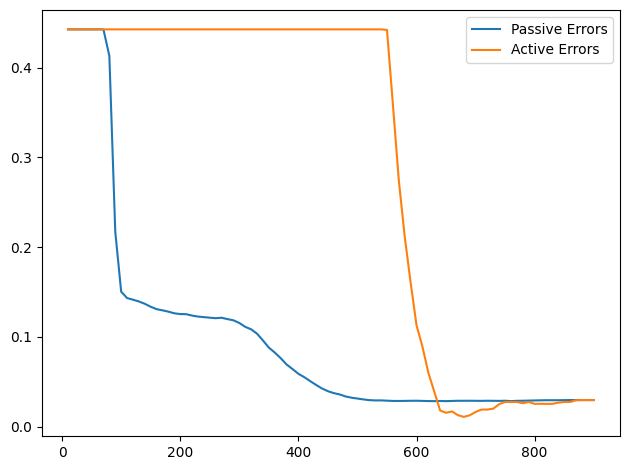

In [97]:
passive_errs_avg = np.array(passive_errs)
active_errs_avg = np.array(active_errs)
instances = np.arange(10, 910, 10)
passive_errs_avg = np.mean(passive_errs_avg, axis=0)
active_errs_avg = np.mean(active_errs_avg, axis=0)
plt.figure()
plt.plot(instances, passive_errs_avg, label='Passive Errors')
plt.plot(instances, active_errs_avg, label='Active Errors')
plt.legend()
plt.tight_layout()
plt.show()